# 2. Pruning and Depth

The problem of notebook 1, with a budget on the LTUs' connections from x and LTUs (biases not counted). Under a
budget, a connection that an LTU does not need takes the room of a connection or an LTU that the network does need.
Can pruning single connections free that room? And can each LTU take its depth from its connections, without fixed
slots per depth?

**Problem.** `problems.SparseTargetNetwork`, as in notebook 1. The target network uses 600 connections. The budget is
1200 connections, 2 times the target network's.

**Baseline.** `algorithms.UnitSearch` of notebook 1 with 48 LTUs (16 per depth), so that each LTU starts with 20
connections and has room to grow 5 more on average. GROW adds connections only while the budget has room. It frees
connections only when SEARCH replaces a whole LTU.

**Proposed.** `algorithms.PruneAndMove`. Lines marked (2) are new:

```
setup     up to 96 LTU slots, each empty or holding an LTU. At step 0, the same LTUs as the baseline.             (2)

every 1k steps
  GROW    as in notebook 1, while the budget has room.

every 10k steps
  PRUNE   each LTU stops reading every layer input whose weight changed sign since the last PRUNE. Connections   (2)
          made since then, and the bias, stay.
  MOVE    each LTU moves down to one depth above the deepest LTU it reads (depth 1 if it reads only x). This     (2)
          replaces SWAP.
  SEARCH  remove the 1/8 of the LTUs with the lowest utility. Then add NEW LTUs in empty slots while the budget  (2)
          has room for 21 connections each.

NEW LTU u
  parent p: a unit of a random layer above depth 1 (the outputs included). u's depth is one below p's layer.     (2)
  The rest as in notebook 1. Only at u's creation does p start to read u.                                        (2)
```

5 seeds, 1M steps, noise std 1.

**Result.** Prune and move ends at RMSE 1.086, and unit search at 1.125. At the end, prune and move holds 96 LTUs
(all its slots) on 919 connections, and unit search 48 LTUs on 1194.

In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import jax
jax.config.update('jax_platforms', 'cuda')

from phd.sandbox.unit_search.algorithm import algorithms, experiment, problems

assert jax.default_backend() == 'gpu'
%matplotlib inline

unit search (baseline): RMSE over the last 10% 1.125 ; at the end, 48 LTUs and 1194 connections from x and LTUs (78s)


prune and move (proposed): RMSE over the last 10% 1.086 ; at the end, 96 LTUs and 919 connections from x and LTUs (89s)


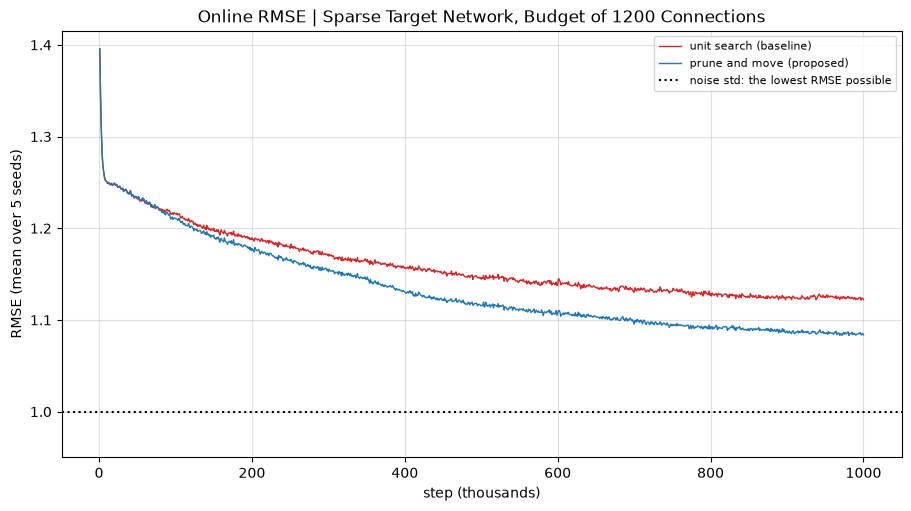

In [2]:
problem = problems.SparseTargetNetwork()
sizes = dict(n_inputs=problem.n_inputs, n_outputs=problem.n_outputs)
budget, width = 1200, 16   # width: LTUs per depth at step 0, 20 connections each plus room to grow 25%
methods = {'unit search (baseline)': algorithms.UnitSearch(**sizes, width=width, budget=budget),
           'prune and move (proposed)': algorithms.PruneAndMove(**sizes, width=width, max_ltus=6 * width,
                                                                 budget=budget)}
rmse, _ = experiment.run(methods, problem, steps=1_000_000)
experiment.plot(rmse, problem, f'Online RMSE | Sparse Target Network, Budget of {budget} Connections')